In [5]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
from src.utils.ds_helper import get_dataset_distribution


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC1.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data02", "train")
test_data_dir = os.path.join(dataset_path, "data02", "test")
val_data_dir = os.path.join(dataset_path, "data02", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data02/train
/Users/joshan/Documents/final-year-project/dataset/data02/test
/Users/joshan/Documents/final-year-project/dataset/data02/val


In [7]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 11873 files belonging to 3 classes.
Found 1392 files belonging to 3 classes.
Found 694 files belonging to 3 classes.


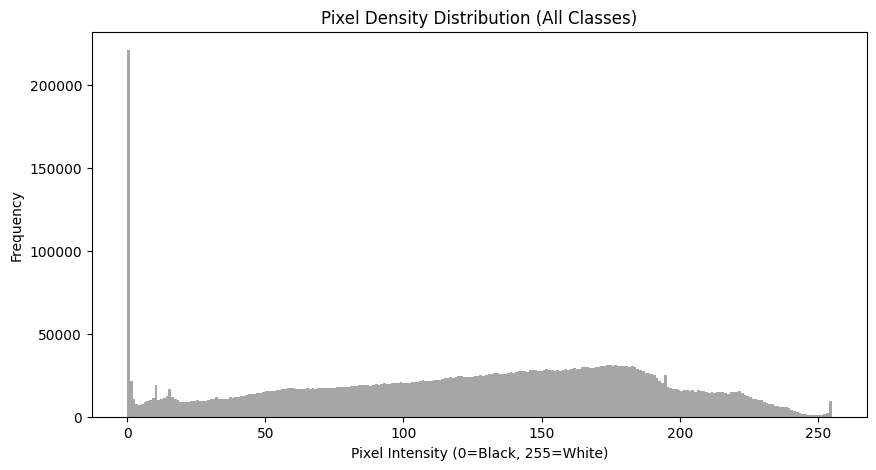

2026-02-24 00:18:16.924213: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Take one batch (e.g., 32 images)
for images, labels in train_ds.take(1):
    # Flatten all pixels in the batch into a 1D array
    pixels = images.numpy().flatten()
    
    plt.figure(figsize=(10, 5))
    plt.hist(pixels, bins=256, color='gray', alpha=0.7)
    plt.title('Pixel Density Distribution (All Classes)')
    plt.xlabel('Pixel Intensity (0=Black, 255=White)')
    plt.ylabel('Frequency')
    plt.show()

2026-02-24 00:18:22.223294: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


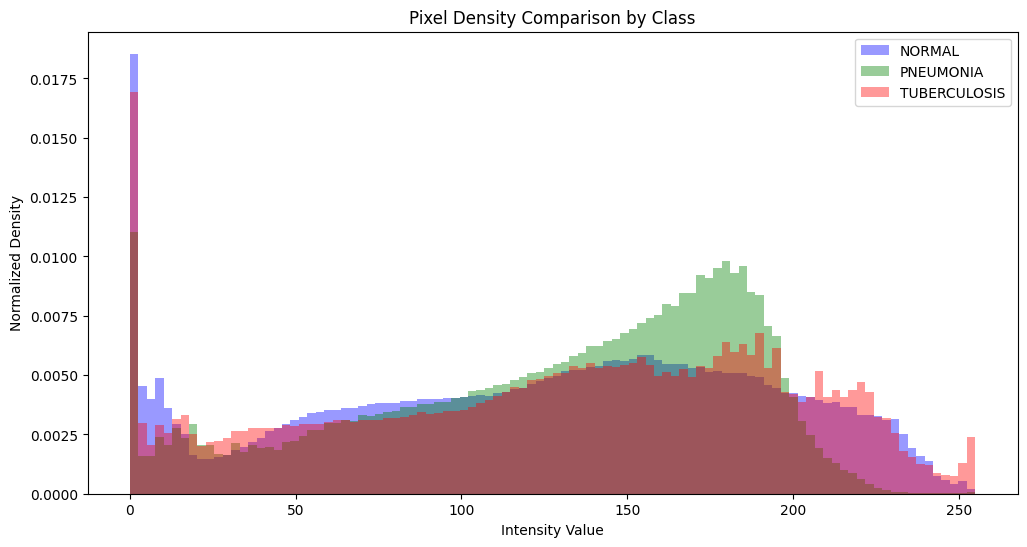

In [15]:
def plot_class_histograms(dataset, class_names):
    plt.figure(figsize=(12, 6))
    
    # Store pixels for each class
    class_pixels = {name: [] for name in class_names}
    
    # Analyze 5 batches for a good sample size
    for images, labels in dataset.take(5):
        images = images.numpy()
        labels = np.argmax(labels.numpy(), axis=1)
        
        for i in range(len(images)):
            cls_name = class_names[labels[i]]
            # Add flattened pixels of this specific image
            class_pixels[cls_name].extend(images[i].flatten())

    # Plotting
    colors = ['blue', 'green', 'red']
    for i, name in enumerate(class_names):
        plt.hist(class_pixels[name], bins=100, alpha=0.4, 
                 label=name, color=colors[i], density=True)

    plt.title('Pixel Density Comparison by Class')
    plt.xlabel('Intensity Value')
    plt.ylabel('Normalized Density')
    plt.legend()
    plt.show()

# Usage
plot_class_histograms(train_ds, train_ds.class_names)

In [2]:
model = models.Sequential([
    # Preprocessing: Rescale inputs to [0, 1]
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    
    # First convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Second convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Third convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),  
    layers.Dropout(0.5), # Helps prevent overfitting by dropping out 0.5 acc 
    layers.Dense(3, activation='softmax') # Softmax for multi-class probability
])

/Users/joshan/Documents/final-year-project/backend/.venv/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
2026-02-24 11:29:18.533963: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-02-24 11:29:18.534086: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-02-24 11:29:18.534103: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-02-24 11:29:18.534337: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-02-24 11:29:18.534666: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Create

In [18]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Epoch 1/10


2026-02-24 00:18:49.979452: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


372/372 ━━━━━━━━━━━━━━━━━━━━ 47s 120ms/step - accuracy: 0.7410 - loss: 0.8187 - val_accuracy: 0.8386 - val_loss: 0.5366
Epoch 2/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 43s 114ms/step - accuracy: 0.8039 - loss: 0.7007 - val_accuracy: 0.8862 - val_loss: 0.2961
Epoch 3/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 42s 113ms/step - accuracy: 0.8463 - loss: 0.5829 - val_accuracy: 0.8674 - val_loss: 0.3908
Epoch 4/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 42s 114ms/step - accuracy: 0.8364 - loss: 0.6539 - val_accuracy: 0.8963 - val_loss: 0.3214
Epoch 5/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 42s 114ms/step - accuracy: 0.8486 - loss: 0.6793 - val_accuracy: 0.9121 - val_loss: 0.3302
Epoch 6/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 42s 114ms/step - accuracy: 0.8438 - loss: 0.9232 - val_accuracy: 0.8905 - val_loss: 0.4742
Epoch 7/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 42s 114ms/step - accuracy: 0.8380 - loss: 1.2234 - val_accuracy: 0.8300 - val_loss: 1.7904
Epoch 8/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 43s 116ms/step - accuracy: 0.8316 - loss: 3.0943 - val

In [19]:
# Save the model
model.save('CXC1.keras')
print("Model saved successfully!")

Model saved successfully!


In [20]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.9045 - loss: 5.7636
Test Loss: 5.763561248779297
Test Accuracy: 90.45%


2026-02-24 00:27:16.787206: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


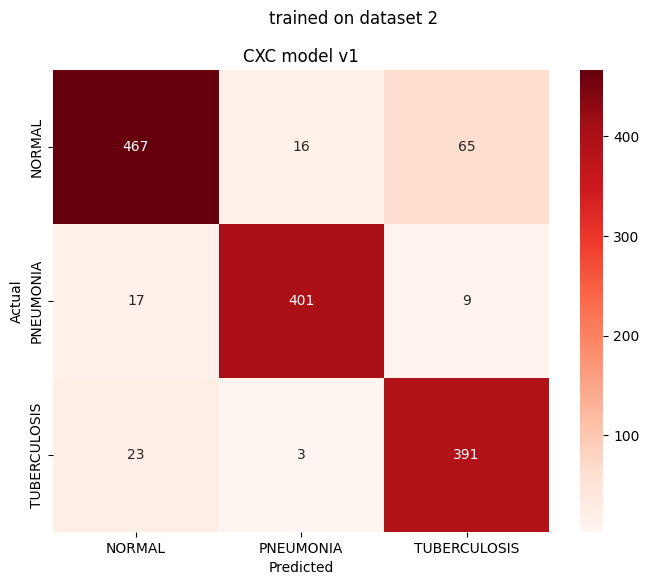

              precision    recall  f1-score   support

      NORMAL       0.92      0.85      0.89       548
   PNEUMONIA       0.95      0.94      0.95       427
TUBERCULOSIS       0.84      0.94      0.89       417

    accuracy                           0.90      1392
   macro avg       0.91      0.91      0.91      1392
weighted avg       0.91      0.90      0.90      1392



In [21]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CXC model v1')
plt.suptitle("trained on dataset 2")
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))

In [25]:
model_path = os.getenv("MODEL_DIR")
model = os.path.join(model_path, "CXC1.keras")
print(model)
model = tf.keras.models.load_model(model)


/Users/joshan/Documents/final-year-project/models/CXC/CXC1.keras


In [27]:
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.8890 - loss: 5.5567
Test Loss: 5.556668758392334
Test Accuracy: 88.90%


# POC: AdamW is better than Adam in terms of accuracy 

In [8]:
model2.compile(
    optimizer='adamw',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model2.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Epoch 1/10


2026-02-24 11:30:13.655561: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


372/372 ━━━━━━━━━━━━━━━━━━━━ 51s 125ms/step - accuracy: 0.7697 - loss: 0.6571 - val_accuracy: 0.8991 - val_loss: 0.2986
Epoch 2/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 44s 116ms/step - accuracy: 0.8625 - loss: 0.4164 - val_accuracy: 0.8948 - val_loss: 0.3302
Epoch 3/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 52s 138ms/step - accuracy: 0.8718 - loss: 0.4299 - val_accuracy: 0.8919 - val_loss: 0.2854
Epoch 4/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 57s 152ms/step - accuracy: 0.8953 - loss: 0.3379 - val_accuracy: 0.9179 - val_loss: 0.2766
Epoch 5/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 51s 136ms/step - accuracy: 0.9043 - loss: 0.3167 - val_accuracy: 0.9236 - val_loss: 0.2612
Epoch 6/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 48s 130ms/step - accuracy: 0.8958 - loss: 0.4049 - val_accuracy: 0.9222 - val_loss: 0.3194
Epoch 7/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 49s 133ms/step - accuracy: 0.8914 - loss: 0.5353 - val_accuracy: 0.9294 - val_loss: 0.3137
Epoch 8/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 50s 134ms/step - accuracy: 0.8914 - loss: 0.7677 - val

2026-02-24 11:40:46.956724: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


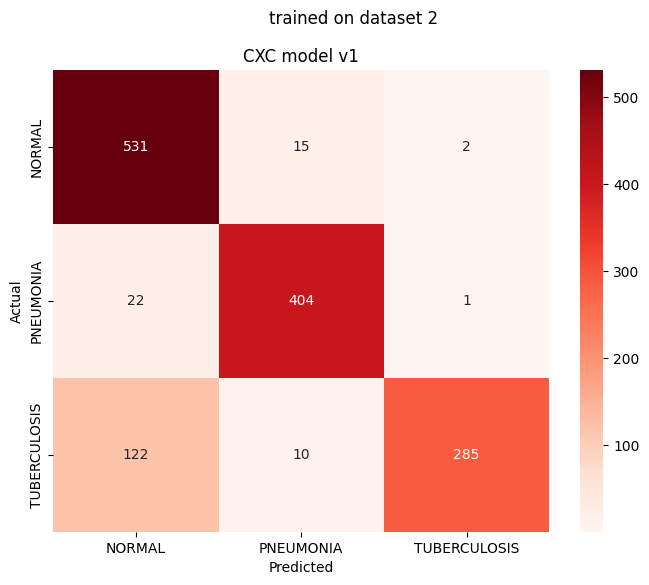

              precision    recall  f1-score   support

      NORMAL       0.79      0.97      0.87       548
   PNEUMONIA       0.94      0.95      0.94       427
TUBERCULOSIS       0.99      0.68      0.81       417

    accuracy                           0.88      1392
   macro avg       0.91      0.87      0.87      1392
weighted avg       0.90      0.88      0.87      1392



In [9]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model2.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CXC model v1')
plt.suptitle("trained on dataset 2")
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))